# 3. Признаки ряда из библиотек: tsfresh, catch22, pyhctsa

Лаги и окна из блоков 1–3 описывают **точку** ряда. Библиотеки в этом блоке дают каталоги
признаков **ряда целиком** — «паспорт» ряда: насколько он трендовый, сезонный, шумный,
предсказуемый. Такой паспорт используется в трёх задачах:
- **понять датасет** — что за ряды перед нами и на что они похожи (этот ноутбук);
- **признаки сегмента** в глобальной модели;
- **выбор модели** по характеристикам ряда — идея FFORMA (упомянем в итогах).

Сегодняшний вопрос: **что именно меряют эти признаки и можно ли им верить?**

План: три библиотеки на одном ряде → разбор признаков на синтетике с известным ответом →
повторяем признаки руками и сверяем с библиотекой → паспорт на 88 реальных рядах.

In [1]:
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pycatch22
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from statsmodels.tsa.seasonal import MSTL
from statsmodels.tsa.stattools import acf
from tsfresh import extract_features
from tsfresh.feature_extraction import EfficientFCParameters
from tsfresh.utilities.dataframe_functions import impute

from common import read_data

warnings.simplefilter("ignore")
plt.rcParams["figure.figsize"] = (12, 4)
plt.rcParams["axes.grid"] = True


def catch22(x) -> pd.Series:
    """22 признака catch22 с короткими именами (`acf_timescale`, `periodicity`, ...)."""
    res = pycatch22.catch22_all(np.asarray(x, dtype=float), short_names=True)
    return pd.Series(res["values"], index=res["short_names"])


def tsfresh_one(x) -> pd.Series:
    """Efficient-набор tsfresh для одного ряда (long-формат собираем внутри)."""
    long = pd.DataFrame({"id": 0, "time": np.arange(len(x)), "value": np.asarray(x, dtype=float)})
    return extract_features(
        long,
        column_id="id",
        column_sort="time",
        default_fc_parameters=EfficientFCParameters(),
        impute_function=impute,
        n_jobs=0,
        disable_progressbar=True,
    ).iloc[0]

## Данные

88 дневных рядов продаж за 2010–2015 (по 2191 точке)

Для паспорта важно, что ряды **разные**: их средние различаются в ~1000 раз,
а формы не совпадают.

In [6]:
data = read_data("daily_sales_train.csv.gz", parse_dates=["timestamp"])
sales = data.pivot(index="timestamp", columns="segment", values="target")
meta = data[["segment", "country", "store", "product"]].drop_duplicates("segment").set_index("segment")
meta = meta.loc[sales.columns]

print(f"рядов: {sales.shape[1]}, точек в каждом: {len(sales)}")
print("средние по рядам:", sales.mean().min(), "…", sales.mean().max())

рядов: 88, точек в каждом: 2191
средние по рядам: 1.6973984481971702 … 1655.6544956640803


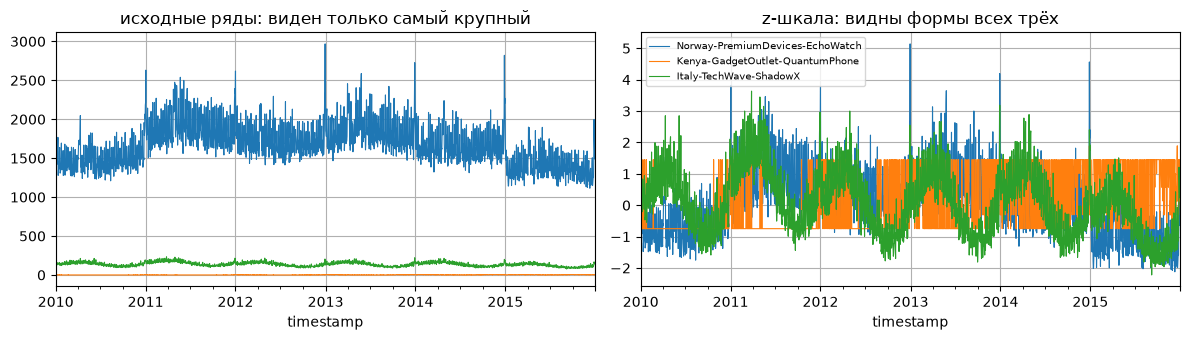

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
example = ["Norway-PremiumDevices-EchoWatch", "Kenya-GadgetOutlet-QuantumPhone", "Italy-TechWave-ShadowX"]
for name in example:
    sales[name].plot(ax=axes[0], label=name, lw=0.8)
    ((sales[name] - sales[name].mean()) / sales[name].std()).plot(ax=axes[1], label=name, lw=0.8)
axes[0].set_title("исходные ряды: виден только самый крупный")
axes[1].set_title("z-шкала: видны формы всех трёх")
axes[1].legend(fontsize=7)
fig.tight_layout()

Масштаб в паспорте — главный подвох: признак, который меняется при умножении ряда на 1000,
в глобальной модели будет работать как «уровень ряда», а не как «форма».

## 1. Три библиотеки, один ряд

Все три решают одну задачу — «посчитать много статистик о ряде» — но с разными компромиссами.

| | Признаков | Время на ряд | Вход | Ограничения |
|---|---|---|---|---|
| `pycatch22` | 22 (24 с mean/std) | ~0.3 мс | `np.ndarray` | сам z-нормирует ряд |
| `tsfresh` | 10 / 777 / ~780 | ~0.1 с (Efficient) | long-таблица | не инвариантен к масштабу |
| `pyhctsa` | ~5200 | ~5 с (ряд 2191) | `np.ndarray` | требует $\geq 100$ точек, ~40 NaN |

Запускаем каждую на одном и том же ряде.

In [8]:
y = sales["Italy-TechWave-ShadowX"]

t = time.perf_counter()
c22 = catch22(y)
t_catch22 = time.perf_counter() - t

t = time.perf_counter()
tsf = tsfresh_one(y)
t_tsfresh = time.perf_counter() - t

t = time.perf_counter()
from pyhctsa.calculator import FeatureCalculator

hctsa = FeatureCalculator().extract(y.to_numpy())
t_hctsa = time.perf_counter() - t

print(f"catch22: {len(c22):5d} признаков, {t_catch22 * 1000:6.1f} мс")
print(f"tsfresh: {len(tsf):5d} признаков, {t_tsfresh:6.2f} с")
print(f"hctsa:   {hctsa.shape[1]:5d} признаков, {t_hctsa:6.2f} с, NaN: {int(hctsa.iloc[0].isna().sum())}")

Loaded 791 master operations.
Evaluating 791 partialed functions. Strap in!...
Feature extraction completed in 5.634 seconds.
catch22:    22 признаков,    9.3 мс
tsfresh:   777 признаков,   0.29 с
hctsa:    5270 признаков,  17.45 с, NaN: 44


Feature extraction completed in 4.127 seconds.
catch22:    22 признаков,    3.8 мс
tsfresh:   777 признаков,   0.14 с
hctsa:    5270 признаков,   8.74 с, NaN: 44


`FeatureCalculator()` сначала собирает список операций из YAML (при самом первом запуске — до ~20 с)
и печатает, сколько их загрузилось; время извлечения печатает отдельно.

### Инвариантность к масштабу

Умножим ряд на 1000 и на сдвиг +500 и посмотрим, что изменилось.

In [9]:
print("catch22 при ×1000:       все 22 совпали —", np.allclose(c22, catch22(1000 * y), rtol=1e-8))
print("catch22 при сдвиге +500: все 22 совпали —", np.allclose(c22, catch22(y + 500), rtol=1e-8))

catch22 при ×1000:       все 22 совпали — True
catch22 при сдвиге +500: все 22 совпали — True


In [10]:
changed = ~np.isclose(tsf.values, tsfresh_one(1000 * y).values, rtol=1e-6, atol=1e-9)
print(f"tsfresh при ×1000: изменилось {changed.sum()} из {len(changed)} признаков")
print("не изменились:", [c.split("__")[1] for c in tsf.index[~changed][:4]])
print("изменились:  ", [c.split("__")[1] for c in tsf.index[changed][:4]])

tsfresh при ×1000: изменилось 498 из 777 признаков
не изменились: ['variance_larger_than_standard_deviation', 'has_duplicate_max', 'has_duplicate_min', 'has_duplicate']
изменились:   ['sum_values', 'abs_energy', 'mean_abs_change', 'mean_change']


catch22 сначала переводит ряд в z-шкалу, поэтому измеряет только **форму**.
tsfresh считает «сырые» статистики и знает **уровень**. Для глобальной модели на рядах
с разными уровнями это разница принципиальная.

## 2. Что меряют признаки: синтетика с известным ответом

Возьмём шесть рядов, про которые заранее известно, «какие они», и посмотрим, упорядочит ли
признак ряды так, как мы ожидаем. Это надёжнее, чем читать определение признака.

- белый шум — нет памяти, нет периода;
- синус периода 24 — строго периодичен;
- случайное блуждание — длинная память, тренд «случайный»;
- тренд — детерминированный рост;
- тренд + синус + шум — всё сразу;
- знаковый шум ($\pm 1$) — максимально нерегулярный.

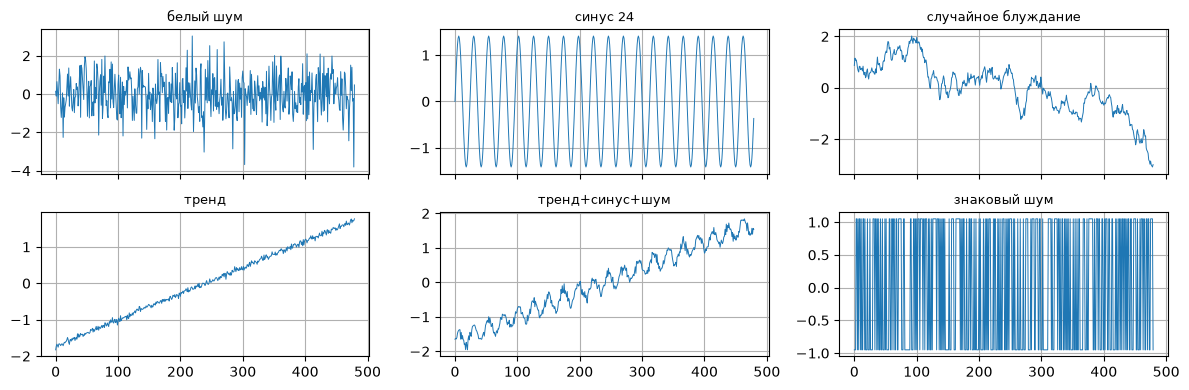

In [11]:
rng = np.random.default_rng(0)
N = 480
t = np.arange(N)


def z(x):
    """z-нормировка; ddof=1 — так же, как внутри catch22."""
    return (x - x.mean()) / x.std(ddof=1)


synthetic = {
    "белый шум": rng.standard_normal(N),
    "синус 24": np.sin(2 * np.pi * t / 24),
    "случайное блуждание": np.cumsum(rng.standard_normal(N)),
    "тренд": 0.05 * t + 0.3 * rng.standard_normal(N),
    "тренд+синус+шум": 0.03 * t + np.sin(2 * np.pi * t / 24) + 0.3 * rng.standard_normal(N),
    "знаковый шум": np.sign(rng.standard_normal(N)),
}
synthetic = {k: z(v) for k, v in synthetic.items()}

fig, axes = plt.subplots(2, 3, figsize=(12, 4), sharex=True)
for ax, (name, x) in zip(axes.ravel(), synthetic.items()):
    ax.plot(x, lw=0.7)
    ax.set_title(name, fontsize=9)
fig.tight_layout()

Считаем паспорт каждого синтетического ряда — сперва catch22.

In [12]:
c22_synth = pd.DataFrame({name: catch22(x) for name, x in synthetic.items()}).T
c22_synth.T.round(3)

,белый шум,синус 24,случайное блуждание,тренд,тренд+синус+шум,знаковый шум
mode_5,-0.386,-0.000,0.487,-0.749,-0.057,-0.750
mode_10,-0.044,-0.000,0.232,-0.569,1.272,-0.850
outlier_timing_pos,-0.025,-0.021,-0.631,0.748,0.756,0.021
outlier_timing_neg,-0.004,0.029,0.923,-0.743,-0.746,-0.017
acf_timescale,0.622,4.564,56.046,104.032,101.992,0.614
acf_first_min,1.000,12.000,81.000,337.000,303.000,1.000
low_freq_power,0.183,0.998,0.977,0.990,0.988,0.173
median_freq,1.608,0.258,0.025,0.012,0.012,1.595
forecast_error,1.172,0.511,0.188,0.049,0.123,1.175
whiten_timescale,0.672,0.990,0.007,0.004,0.004,0.686


Строчки — ряды, столбцы — признаки. Читаем по столбцам.

### `acf_timescale` — за сколько шагов ряд «забывает» прошлое

Первое пересечение ACF с уровнем $1/e$. У белого шума — единицы, у случайного блуждания —
десятки. Это тот же смысл, что «память ряда».

In [13]:
c22_synth["acf_timescale"].sort_values().round(2)

знаковый шум             0.61
белый шум                0.62
синус 24                 4.56
случайное блуждание     56.05
тренд+синус+шум        101.99
тренд                  104.03
Name: acf_timescale, dtype: float64

### `periodicity` — оценка периода (`PD_PeriodicityWang`)

Ищет период по автокорреляции. У синуса — 24. У белого шума и знакового шума — «нет периода» (малые значения).

In [14]:
c22_synth["periodicity"].sort_values().round(2)

тренд                    0.0
белый шум                4.0
знаковый шум             4.0
синус 24                24.0
тренд+синус+шум         24.0
случайное блуждание    131.0
Name: periodicity, dtype: float64

### `acf_first_min` — лаг первого минимума ACF

Для синуса — половина периода (12), для блуждания — десятки: сигнал «так далеко прошлое ещё влияет».

In [15]:
c22_synth["acf_first_min"].sort_values().round(2)

белый шум                1.0
знаковый шум             1.0
синус 24                12.0
случайное блуждание     81.0
тренд+синус+шум        303.0
тренд                  337.0
Name: acf_first_min, dtype: float64

### `stretch_high` — самый длинный участок выше среднего

У тренда и блуждания — сотни точек, у шума — единицы. Мера «медленности» ряда.

In [16]:
c22_synth["stretch_high"].sort_values().round(2)

белый шум                7.0
знаковый шум             7.0
синус 24                13.0
случайное блуждание    122.0
тренд+синус+шум        218.0
тренд                  234.0
Name: stretch_high, dtype: float64

### `forecast_error` — ошибка прогноза «средним трёх предыдущих»

Прямая мера предсказуемости по прошлому: ≈1 у белого шума и знакового шума, у синуса 0.51,
у блуждания 0.19 (предыдущие значения почти равны следующему), у тренда 0.05.

In [17]:
c22_synth["forecast_error"].sort_values().round(2)

тренд                  0.05
тренд+синус+шум        0.12
случайное блуждание    0.19
синус 24               0.51
белый шум              1.17
знаковый шум           1.17
Name: forecast_error, dtype: float64

### `low_freq_power` (`SP_Summaries_fft_area_5_1`) — доля мощности на низких частотах

~1 у плавных рядов (тренд, синус), ~0.2 у шума. Мера «гладкости».

In [18]:
c22_synth["low_freq_power"].sort_values().round(2)

знаковый шум           0.17
белый шум              0.18
случайное блуждание    0.98
тренд+синус+шум        0.99
тренд                  0.99
синус 24               1.00
Name: low_freq_power, dtype: float64

Три признака, которых нет в catch22, считаем сами по формулам лонгрида §2.2.2:
силу тренда и сезонности через MSTL и экспоненту Хёрста.

In [20]:
def stl_strengths(x, periods=(24,)):
    """Сила тренда и сезонности: 1 - var(остаток) / var(компонента + остаток)."""
    res = MSTL(np.asarray(x, dtype=float), periods=periods).fit()
    resid = np.asarray(res.resid, dtype=float)
    seasonal = np.asarray(res.seasonal, dtype=float).reshape(len(resid), -1)  # столбец на каждый период
    out = {"trend_strength": 1 - np.var(resid) / np.var(np.asarray(res.trend) + resid)}
    for i, period in enumerate(periods):
        out[f"seasonal_{period}_strength"] = 1 - np.var(resid) / np.var(seasonal[:, i] + resid)
    return {k: float(max(0, v)) for k, v in out.items()}


def hurst(x, sizes=(8, 16, 32, 64, 120)):
    """Показатель Хёрста (R/S-анализ): наклон log(R/S) от log(n) по блокам длины n."""
    rs = []
    for n in sizes:
        blocks = x[: len(x) // n * n].reshape(-1, n)
        dev = np.cumsum(blocks - blocks.mean(axis=1, keepdims=True), axis=1)
        rs.append(np.mean((dev.max(axis=1) - dev.min(axis=1)) / blocks.std(axis=1)))
    return np.polyfit(np.log(sizes), np.log(rs), 1)[0]


own = pd.DataFrame(
    {name: {**stl_strengths(x), "hurst": hurst(x)} for name, x in synthetic.items()}
).T
own.round(3)

,trend_strength,seasonal_24_strength,hurst
белый шум,0.060,0.287,0.570
синус 24,0.000,1.000,0.444
случайное блуждание,0.954,0.139,0.942
тренд,0.999,0.262,1.113
тренд+синус+шум,0.996,0.889,0.914
знаковый шум,0.073,0.250,0.529


Сила тренда различает тренд и блуждание от шума, сила сезонности — синус от остальных.
Хёрст: у шума ≈ 0.5–0.6 (нет памяти), у блуждания ≈ 0.9, у тренда > 1 (персистентность),
у синуса < 0.5 (возврат к среднему). На коротких рядах R/S-оценка смещена вверх — для белого
шума теоретическое значение 0.5.

## 3. Паспорт на реальных 88 рядах

Считаем catch22 и STL-признаки для всех рядов. catch22 на 88 рядах — доли секунды, MSTL — около
40 секунд (два сезона, 7 и 365).

In [21]:
t = time.perf_counter()
c22_real = pd.DataFrame({c: catch22(sales[c]) for c in sales}).T
print(f"catch22: {time.perf_counter() - t:.1f} с, {c22_real.shape[1]} признаков")

t = time.perf_counter()
stl = pd.DataFrame({c: stl_strengths(sales[c], periods=(7, 365)) for c in sales}).T
print(f"MSTL: {time.perf_counter() - t:.1f} с")
passport = c22_real.join(stl)

catch22: 0.3 с, 22 признаков
MSTL: 42.6 с


MSTL: 40.8 с


### Сортировки по признаку

Так ищут ряды «с особенностью»: экстремумы признака — кандидаты на то, чтобы посмотреть глазами.

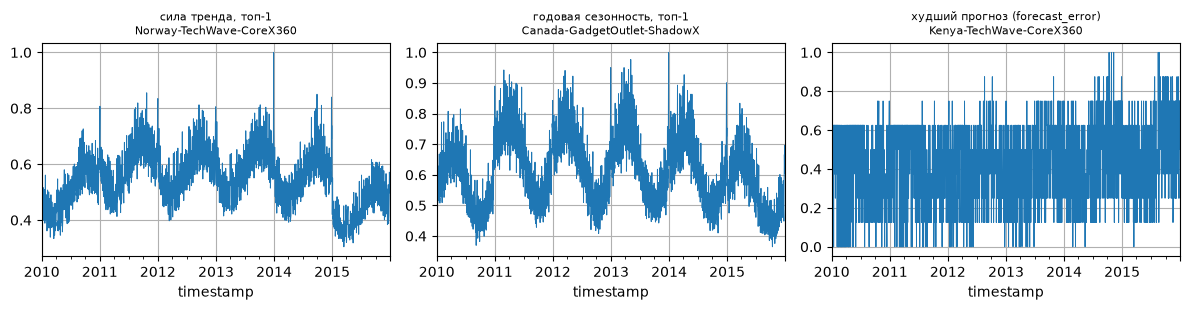

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2))
for ax, col, title in zip(
    axes,
    ["trend_strength", "seasonal_365_strength", "forecast_error"],
    ["сила тренда, топ-1", "годовая сезонность, топ-1", "худший прогноз (forecast_error)"],
):
    name = passport[col].idxmax()
    (sales[name] / sales[name].max()).plot(ax=ax, lw=0.7)
    ax.set_title(f"{title}\n{name}", fontsize=8)
fig.tight_layout()

Что видно:
- «самый трендовый» ряд — это не рост, а **сдвиги уровня** (провал в 2015): тренд MSTL — это всё
  медленное, что не попало в сезонность. Признак верно меряет «долю медленной компоненты», а
  словесное «трендовый» надо проверять глазами;
- самый сезонный ряд — продажи с выраженным годовым циклом;
- худший `forecast_error` — ряд с продажами 0–8 штук в день: это **счётные данные**, у них шум
  сравним с уровнем. Паспорт нашёл ряд, для которого нужна отдельная модель (Пуассон / Кростон).

In [23]:
passport[["trend_strength", "seasonal_7_strength", "seasonal_365_strength"]].describe().round(3)

,trend_strength,seasonal_7_strength,seasonal_365_strength
count,88.000,88.000,88.000
mean,0.693,0.707,0.722
std,0.132,0.125,0.177
min,0.072,0.292,0.392
25%,0.646,0.720,0.568
50%,0.723,0.747,0.744
75%,0.764,0.775,0.892
max,0.849,0.821,0.937


Все ряды различаются по силе тренда (0.07–0.85) и годовой сезонности (0.39–0.94),
недельная сезонность везде умеренная. Значит, датасет неоднородный и его есть смысл
группировать.

### Карта рядов (instance space)

Вместо того чтобы смотреть 88 графиков, спроецируем
признаки в две оси (PCA) и посмотрим, где какие ряды. Метод используется для выбора модели
по свойствам ряда.

In [24]:
Z = StandardScaler().fit_transform(c22_real)
pca = PCA(n_components=2).fit(Z)
coords = pd.DataFrame(pca.transform(Z), index=passport.index, columns=["PC1", "PC2"])
print("доля дисперсии:", pca.explained_variance_ratio_.round(2), "сумма:", pca.explained_variance_ratio_.sum().round(2))

доля дисперсии: [0.31 0.2 ] сумма: 0.51


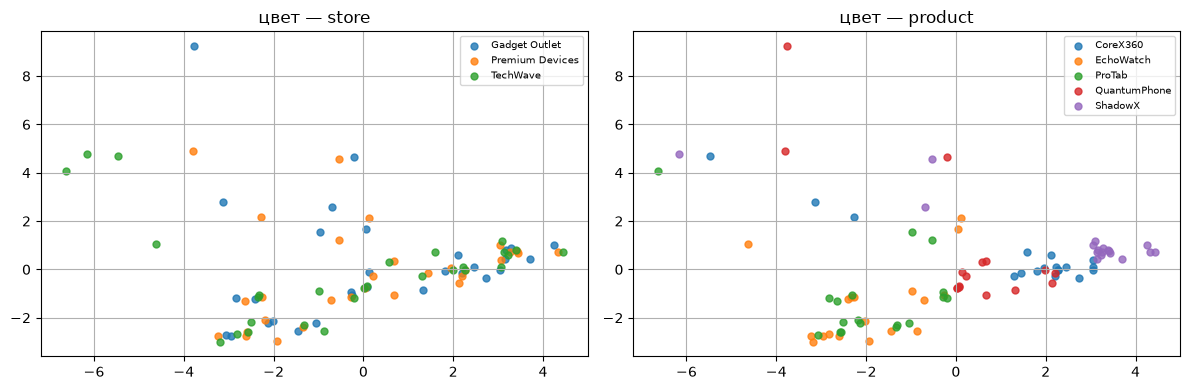

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, col in zip(axes, ["store", "product"]):
    for group, part in coords.groupby(meta[col]):
        ax.scatter(part["PC1"], part["PC2"], s=25, label=group, alpha=0.8)
    ax.set_title(f"цвет — {col}")
    ax.legend(fontsize=7)
fig.tight_layout()

Ряды группируются по **продукту** (PC2), а по магазину — слабее (PC1). То есть форма спроса
определяется товаром сильнее, чем точкой продаж — полезное наблюдение, которое из 88 графиков
не вычитать.

И главное: обе оси — линейные комбинации 22 признаков. Это и есть instance space: карта,
на которой потом можно отмечать «какая модель работает на каком участке» — так выбирают
модель по свойствам ряда, не перебирая все модели на всех рядах.

### Сколько признаков «независимы»

22 признака catch22 сильно коррелируют между собой: часть меряет одно и то же по-разному.

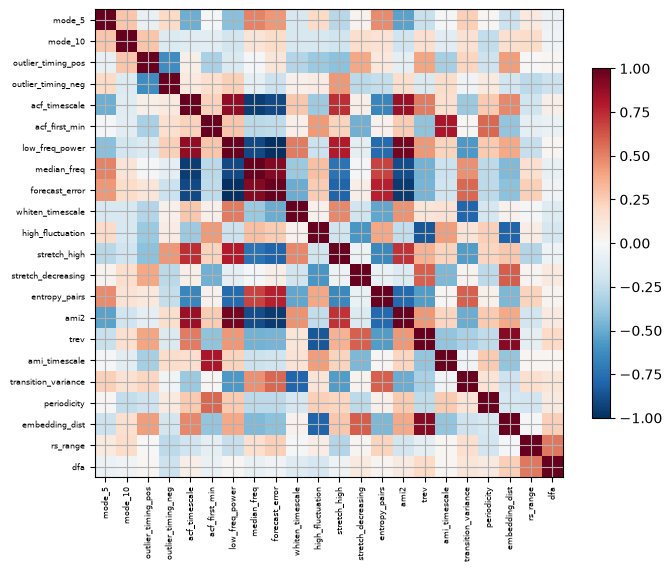

In [26]:
corr = c22_real.corr(method="spearman")
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=90, fontsize=6)
ax.set_yticks(range(len(corr)), corr.columns, fontsize=6)
fig.colorbar(im, shrink=0.7)
fig.tight_layout()

In [27]:
explained = PCA().fit(StandardScaler().fit_transform(c22_real)).explained_variance_ratio_.cumsum()
print("пар признаков с |ρ| > 0.9:", int(((corr.abs() > 0.9).to_numpy().sum() - len(corr)) / 2))
print("компонент на 80% дисперсии:", int(np.argmax(explained >= 0.8)) + 1)

пар признаков с |ρ| > 0.9: 8
компонент на 80% дисперсии: 6


На 22 признака хватает 5–6 независимых осей. Значит, для модели достаточно взять 5–6 признаков
или использовать PCA, а не все 22 — вернёмся к этому в 9.D.2.

catch22 — это выжимка hctsa: у каждого из 22 признаков в паспорте `pyhctsa` (5270 столбцов)
нашёлся почти точный аналог — на подвыборке рядов у большинства $|\rho| \geq 0.99$.
Остальные тысячи столбцов — другие операции, и большая часть из них почти константна
на наших рядах.

## 4. Итоги

| Вопрос | Ответ |
|---|---|
| Что такое паспорт ряда | Каталог статистик по всему ряду: тренд, сезонность, память, предсказуемость, гладкость |
| Как проверить, что признак меряет | Синтетика с известным ответом + пересчёт руками со сверкой `np.allclose` |
| catch22, tsfresh, hctsa | 22 быстрых признака формы / 777 сырых статистик / 5200 операций, требуют $\geq 100$ точек |
| Главный подвох | Масштаб: catch22 инвариантен, tsfresh — нет; в глобальной модели это разные роли |
| Зачем всё это | Понять датасет, найти группы рядов, выбрать модель по свойствам |

Следующий ноутбук — использовать паспорт там, где он может добавить точности: в глобальной
модели на всех 88 рядах.